In [70]:
import numpy as np
import matplotlib.pyplot as plt

data = np.genfromtxt('data/iris_full.csv', delimiter=',', skip_header=1)
data

array([[5.1, 3.5, 1.4, 0.2, 0. ],
       [4.9, 3. , 1.4, 0.2, 0. ],
       [4.7, 3.2, 1.3, 0.2, 0. ],
       [4.6, 3.1, 1.5, 0.2, 0. ],
       [5. , 3.6, 1.4, 0.2, 0. ],
       [5.4, 3.9, 1.7, 0.4, 0. ],
       [4.6, 3.4, 1.4, 0.3, 0. ],
       [5. , 3.4, 1.5, 0.2, 0. ],
       [4.4, 2.9, 1.4, 0.2, 0. ],
       [4.9, 3.1, 1.5, 0.1, 0. ],
       [5.4, 3.7, 1.5, 0.2, 0. ],
       [4.8, 3.4, 1.6, 0.2, 0. ],
       [4.8, 3. , 1.4, 0.1, 0. ],
       [4.3, 3. , 1.1, 0.1, 0. ],
       [5.8, 4. , 1.2, 0.2, 0. ],
       [5.7, 4.4, 1.5, 0.4, 0. ],
       [5.4, 3.9, 1.3, 0.4, 0. ],
       [5.1, 3.5, 1.4, 0.3, 0. ],
       [5.7, 3.8, 1.7, 0.3, 0. ],
       [5.1, 3.8, 1.5, 0.3, 0. ],
       [5.4, 3.4, 1.7, 0.2, 0. ],
       [5.1, 3.7, 1.5, 0.4, 0. ],
       [4.6, 3.6, 1. , 0.2, 0. ],
       [5.1, 3.3, 1.7, 0.5, 0. ],
       [4.8, 3.4, 1.9, 0.2, 0. ],
       [5. , 3. , 1.6, 0.2, 0. ],
       [5. , 3.4, 1.6, 0.4, 0. ],
       [5.2, 3.5, 1.5, 0.2, 0. ],
       [5.2, 3.4, 1.4, 0.2, 0. ],
       [4.7, 3

In [71]:
X = data[:, :-1]
Y = data[:, -1]

In [72]:
X = np.hstack((np.ones((X.shape[0], 1)), X))

In [73]:
print(X.shape)
print(Y.shape)

(100, 5)
(100,)


In [74]:
N = len(X)

In [75]:
def sigmoid_function(z):
    return 1 / (1 + np.exp(-z))


def predict(theta, x):
    z = x.dot(theta)
    y_hat = sigmoid_function(z)
    return y_hat

def compute_loss(y_hat, y):
    loss = -(y.T.dot(np.log(y_hat)) + (1 - y).T.dot(np.log(1 - y_hat))) / N
    return loss

def compute_gradient(x, y_hat, y):
    return 1 / N * x.T.dot(y_hat - y)

def update_weight(theta, gradient, lr):
    theta = theta - lr * gradient
    return theta


In [76]:
epoch_max = 100
losses = []
lr = 0.1
theta = np.random.rand(X.shape[1])
print(theta.shape)
for _ in range(epoch_max):
    y_hat = predict(theta, X)

    loss = compute_loss(y_hat, Y)
    losses.append(loss)
    gradient = compute_gradient(X, y_hat, Y)

    theta = update_weight(theta, gradient, lr)

print(theta)

(5,)
[ 0.18257072 -0.711189   -0.62736399  1.71672146  1.15547928]


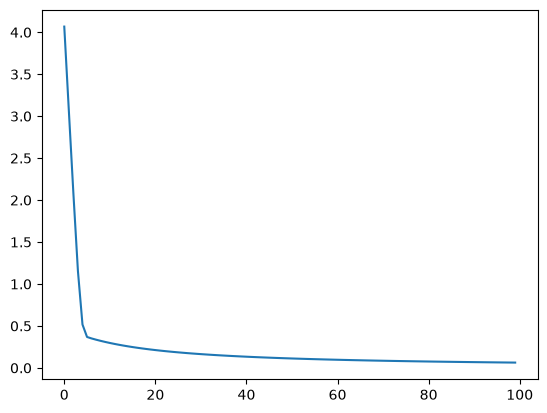

In [77]:
plt.plot(losses)

In [ ]:
preds = []
for i in range(len(X)):
    x = X[i, :]
    y = Y[i]

    y_hat = predict(theta, x)
    preds.append(y_hat)

(y == np.array(preds).round()).mean()